In [ ]:
!pip install transformers torch librosa soundfile tensorflow keras ultralytics pillow requests -q

import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

Установка библиотек...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 760.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 7.0 MB/s eta 0:00:00
Библиотеки установлены!


In [ ]:
#анализ тональности текста
from transformers import pipeline

classifier = pipeline("sentiment-analysis", model="blanchefort/rubert-base-cased-sentiment")

texts = [
    "Этот курс просто потрясающий, я узнал очень много нового!",
    "Ужасный сервис, ничего не работает, деньги на ветер.",
    "Я сегодня ходил в магазин, купил мороженое.",
    "Я люблю учится, но мне безумно скучно сидеть на парах."
]

results = classifier(texts)

for text, res in zip(texts, results):
    print(f"Текст: '{text}'")
    print(f"Результат: {res['label']} (Уверенность: {res['score']:.2%})\n")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Текст: 'Этот курс просто потрясающий, я узнал очень много нового!'
Результат: POSITIVE (Уверенность: 90.60%)

Текст: 'Ужасный сервис, ничего не работает, деньги на ветер.'
Результат: NEGATIVE (Уверенность: 75.15%)

Текст: 'Я сегодня ходил в магазин, купил мороженое.'
Результат: NEUTRAL (Уверенность: 81.09%)

Текст: 'Я люблю учится, но мне безумно скучно сидеть на парах.'
Результат: NEGATIVE (Уверенность: 75.16%)



In [ ]:
#распознавание речи
!apt-get update -qq
!apt-get install -y -qq ffmpeg

from transformers import pipeline
import librosa

whisper_pipeline = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny"
)

!wget -q -O test_audio.flac "https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/1.flac"

audio1, sr1 = librosa.load("test_audio.flac", sr=16000)
result1 = whisper_pipeline(audio1, language="english", task="transcribe")
print(f"распознанный текст: {result1['text']}\n")

filename = "voice.ogg"

audio2, sr2 = librosa.load(filename, sr=16000)
result2 = whisper_pipeline(audio2, language="russian", task="transcribe")
print(f"распознанный текст: {result2['text']}\n")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

распознанный текст:  He hoped there would be stew for dinner, turnips and carrots and bruised potatoes and fat mutton pieces to be ladled out in thick, peppered flour-fat and sauce.

распознанный текст:  Мне очень нравится учиться и я очень люблю изучать что-то новое.



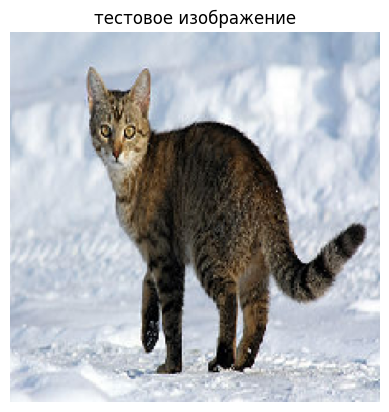

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

топ-3 предсказания модели:
- shower_curtain (ID: n04209239): 43.11%
- window_screen (ID: n04589890): 9.48%
- pillow (ID: n03938244): 4.17%


In [ ]:
#классификация изображений
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions
from tensorflow.keras.utils import load_img, img_to_array
import urllib.request

model = MobileNetV2(weights='imagenet')

img_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/320px-Felis_catus-cat_on_snow.jpg"
img_path = "test_cat.jpg"

req = urllib.request.Request(img_url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response, open(img_path, 'wb') as out_file:
    out_file.write(response.read())

img = load_img(img_path, target_size=(224, 224))
plt.imshow(img)
plt.axis('off')
plt.title("тестовое изображение")
plt.show()

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

preds = model.predict(img_array)

print("\nтоп-3 предсказания модели:")
for label, desc, prob in decode_predictions(preds, top=3)[0]:
    print(f"- {desc} (ID: {label}): {prob*100:.2f}%")


image 1/1 /content/test_frame.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 530.4ms
Speed: 11.5ms preprocess, 530.4ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict-3

детекция завершена!
найдено объектов: 6

найденные объекты:
- bus: 87.3%
- person: 86.6%
- person: 85.3%
- person: 82.5%
- person: 26.1%
- stop sign: 25.5%


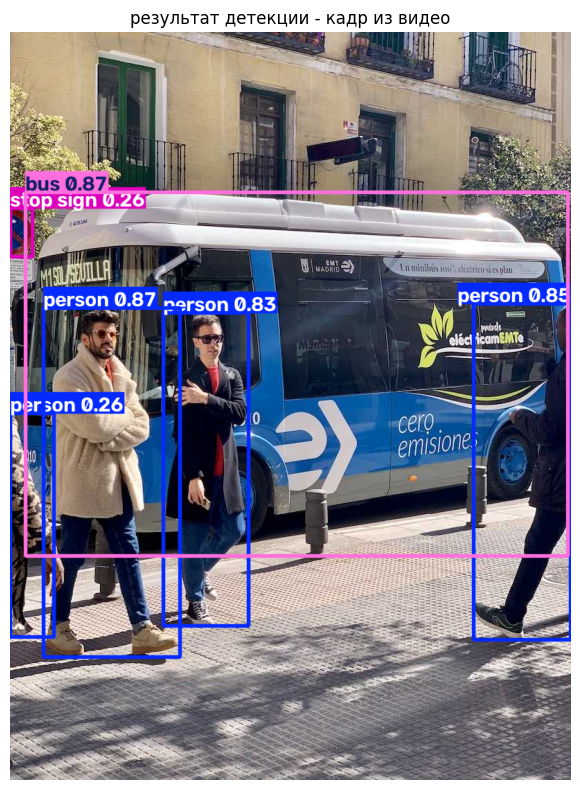

In [ ]:
#детекция объектов
from ultralytics import YOLO
import cv2
import urllib.request

model = YOLO('yolov8n.pt')

img_url = "https://ultralytics.com/assets/bus.jpg"
img_path = "test_frame.jpg"

req = urllib.request.Request(img_url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response, open(img_path, 'wb') as out_file:
    out_file.write(response.read())

results = model.predict(source=img_path, show=False, save=True)

print("\nдетекция завершена!")

if len(results[0].boxes) > 0:
    boxes = results[0].boxes
    print(f"найдено объектов: {len(boxes)}")
    print("\nнайденные объекты:")
    for i, (cls, conf) in enumerate(zip(boxes.cls, boxes.conf)):
        print(f"- {model.names[int(cls)]}: {conf*100:.1f}%")
else:
    print("объекты не найдены")

result_frame = results[0].plot()
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_frame, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.tight_layout()
plt.show()